# 03 · Neural network

This notebook trains the neural network, compares it with the logistic regression baselines and analyses its errors on the cv set:

1. **Hyperparameters:** the fraud weight, the learning rate and when to stop, chosen with searches that run outside the notebook.
2. **Training:** the final network and its learning curves.
3. **Comparison:** the network against the baselines on PR-AUC.
4. **Error analysis:** which frauds the network misses, which legit purchases it flags, and why.

The test set is not used here; it stays untouched until the final evaluation.

In [1]:
# Reload the project packages automatically, so code edits show up without restarting the kernel.
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
import tensorflow as tf

from fraud_core.features import Preprocessor
from fraud_training.data import load_raw, split_by_time
from fraud_training.error_analysis import NIGHT_HOURS, card_history, count_tags, sample_errors
from fraud_training.evaluate import confusion, evaluate, plot_pr_curves, results_table
from fraud_training.train import train_logistic, train_neural_net

In [3]:
split = split_by_time(load_raw())
prep = Preprocessor().fit(split.train)
X_train, y_train = prep.transform(split.train)
X_cv, y_cv = prep.transform(split.cv)

## Choosing the hyperparameters

### Fraud weight

`class_weight` makes each fraud count more in the cost function. Too little and the network ignores frauds; too much and it becomes paranoid. The right value is a hyperparameter, so it was picked on the cv set by `fraud_training.tune_fraud_weight`: five weights, three seeds each, with everything else fixed. The script saves its results, loaded below.

In [4]:
search = pd.read_csv("../reports/fraud_weight_search.csv")
search.groupby("fraud_weight").agg(
    pr_auc_mean=("pr_auc", "mean"),
    pr_auc_std=("pr_auc", "std"),
    missed_frauds=("missed_frauds", "mean"),
    false_alarms=("false_alarms", "mean"),
).round(3)

,pr_auc_mean,pr_auc_std,missed_frauds,false_alarms
fraud_weight,,,,
1,0.534,0.102,1756.000,95.000
10,0.736,0.059,456.333,1169.333
50,0.649,0.047,177.333,5170.333
176,0.546,0.067,56.333,14725.333
400,0.459,0.052,28.333,24771.667


A weight of 10 gives the best PR-AUC by a margin larger than the run-to-run variation. Larger weights keep cutting missed frauds at the 0.5 threshold, but they multiply false alarms and make the ranking itself worse. Without any weight (1), training is unstable: one of the three seeds learned to flag almost nothing.

### Learning rate and when to stop

With the weight fixed at 10, the learning curves were still going down at epoch 100: training stopped before the network had finished learning. `fraud_training.tune_training` compares three ways to train it, three seeds each:

- the original small learning rate (1e-4) for a fixed 100 epochs;
- a 10x larger learning rate (1e-3) with early stopping;
- the small learning rate with early stopping and room for up to 300 epochs.

Early stopping checks J_cv after every epoch. Once it has not improved for 10 epochs in a row, training stops and the network rolls back to the weights of its best epoch.

In [5]:
runs = pd.read_csv("../reports/training_search.csv")
runs.groupby("setup", sort=False).agg(
    pr_auc_mean=("pr_auc", "mean"),
    pr_auc_std=("pr_auc", "std"),
    best_epoch=("best_epoch", "mean"),
    minutes=("minutes", "mean"),
).round(3)

,pr_auc_mean,pr_auc_std,best_epoch,minutes
setup,,,,
"lr 1e-4, 100 epochs",0.736,0.059,100.000,1.211
"lr 1e-3, early stopping",0.855,0.022,179.667,2.079
"lr 1e-4, early stopping",0.804,0.044,300.000,3.406


The larger learning rate with early stopping wins: PR-AUC rises from 0.74 to 0.86, with less variation between seeds, and each run is faster. With the small learning rate even 300 epochs are not enough: all three runs hit the limit while still improving.

## Build and train

`train_neural_net` in `fraud_training.train` builds the network, gives the cv set the same fraud weight as train (so J_train and J_cv are on the same scale) and trains with early stopping. It is the same function the searches above used, so this run reproduces seed 0 of the winning setup.

In [6]:
FRAUD_WEIGHT = 10     # best PR-AUC in the weight search
LEARNING_RATE = 1e-3  # best PR-AUC in the training search
MAX_EPOCHS = 300
PATIENCE = 10         # epochs without J_cv improvement before stopping
SEED = 0              # fixes the random starting weights, so the run is repeatable

model, history = train_neural_net(
    X_train, y_train, X_cv, y_cv,
    fraud_weight=FRAUD_WEIGHT,
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
    seed=SEED,
)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Trained for {len(history.history['val_loss'])} epochs; best epoch: {best_epoch}")
model.summary()

Trained for 300 epochs; best epoch: 300


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 677 (2.65 KB)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 452 (1.77 KB)

## Learning curves: J_train vs J_cv

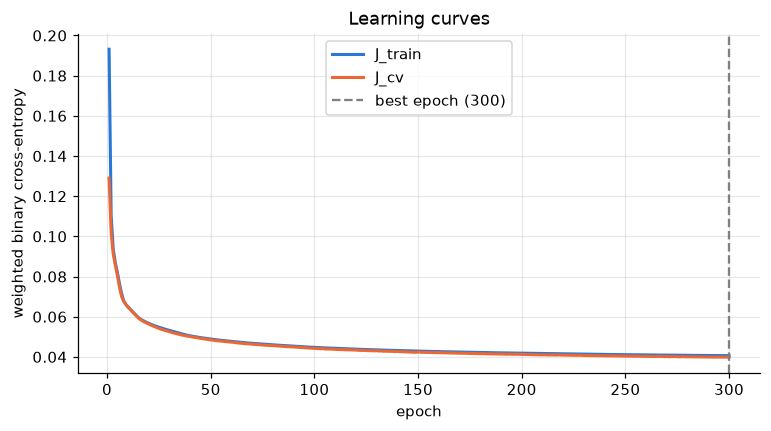

In [7]:
train_loss = history.history["loss"]
cv_loss = history.history["val_loss"]
epochs = range(1, len(train_loss) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs, train_loss, lw=2, label="J_train")
ax.plot(epochs, cv_loss, lw=2, label="J_cv")
ax.axvline(best_epoch, ls="--", c="gray", label=f"best epoch ({best_epoch})")
ax.set_xlabel("epoch")
ax.set_ylabel("weighted binary cross-entropy")
ax.set_title("Learning curves")
ax.legend()
fig.savefig(FIGURES / "nn_learning_curves.png", bbox_inches="tight")

## Compare with the baseline

In [8]:
# The baselines are retrained on the same split, so every model is scored on the same cv set.
# The lazy model is left out: its PR curve is the dashed "random" line in the plot below.
baselines = {
    "logistic": train_logistic(X_train, y_train),
    "logistic (balanced)": train_logistic(X_train, y_train, class_weight="balanced"),
}
probs = {name: m.predict_proba(X_cv)[:, 1] for name, m in baselines.items()}
probs["neural net"] = model.predict(X_cv, verbose=0).ravel()

results_table({name: evaluate(y_cv, p) for name, p in probs.items()})

,accuracy,precision,recall,f1,pr_auc,roc_auc
neural net,0.9970,0.7183,0.8412,0.7749,0.8755,0.9964
logistic,0.9942,0.7059,0.0840,0.1501,0.3505,0.8435
logistic (balanced),0.7484,0.0179,0.7428,0.0350,0.1653,0.8598


Where do the neural net's errors fall at the default 0.5 threshold?

In [9]:
confusion(y_cv, probs["neural net"])

,pred: legit,pred: fraud
actual: legit,368785,754
actual: fraud,363,1923


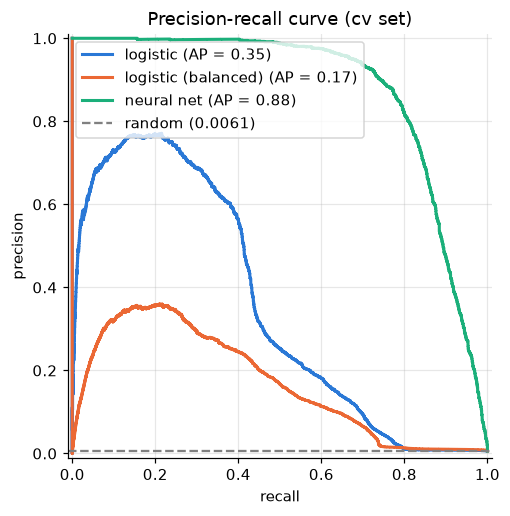

In [10]:
ax = plot_pr_curves(y_cv, probs)
ax.figure.savefig(FIGURES / "pr_curve_comparison.png", bbox_inches="tight")

## Error analysis

Which frauds does the network miss? To find out, put the network's score next to the original, readable columns and compare three groups: the frauds it caught, the frauds it missed, and legit transactions.

The threshold stays at 0.5 for now; choosing it by cost comes later (step 6).

In [11]:
THRESHOLD = 0.5

# split.cv holds the raw cv rows in the same order as X_cv, so the scores line up.
cv = split.cv.assign(score=probs["neural net"], hour=split.cv["trans_date_trans_time"].dt.hour)
frauds = cv[cv["is_fraud"] == 1]
caught = frauds[frauds["score"] >= THRESHOLD]
missed = frauds[frauds["score"] < THRESHOLD]
legit = cv[cv["is_fraud"] == 0]
print(f"Frauds in cv: {len(frauds)} | caught: {len(caught)} | missed: {len(missed)}")

Frauds in cv: 2286 | caught: 1923 | missed: 363


### How do missed frauds differ from caught ones?

In [12]:
groups = {"missed frauds": missed, "caught frauds": caught, "legit": legit}
pd.DataFrame({
    name: {
        "transactions": len(g),
        "median amount": g["amt"].median(),
        "share at night (22h-3h)": g["hour"].isin(NIGHT_HOURS).mean(),
        "median score": g["score"].median(),
    }
    for name, g in groups.items()
}).round(3)

,missed frauds,caught frauds,legit
transactions,363.000,1923.000,369539.000
median amount,20.670,736.280,47.550
share at night (22h-3h),0.697,0.879,0.232
median score,0.196,0.986,0.000


Share of frauds missed in each slice of amount and time of day:

In [13]:
frauds = frauds.assign(missed=frauds["score"] < THRESHOLD)
by_amount = frauds.groupby(pd.cut(frauds["amt"], [0, 20, 50, 100, 300, frauds["amt"].max()]), observed=True)["missed"].mean()
by_time = frauds.groupby(frauds["hour"].isin(NIGHT_HOURS).map({True: "night (22h-3h)", False: "day (4h-21h)"}))["missed"].mean()
pd.concat({"by amount": by_amount, "by time of day": by_time}).rename("share missed").round(3).to_frame()

share missed
by amount      (0.0, 20.0]              0.456
               (20.0, 50.0]             0.808
               (50.0, 100.0]            0.900
               (100.0, 300.0]           0.190
               (300.0, 1376.04]         0.032
by time of day day (4h-21h)             0.322
               night (22h-3h)           0.130

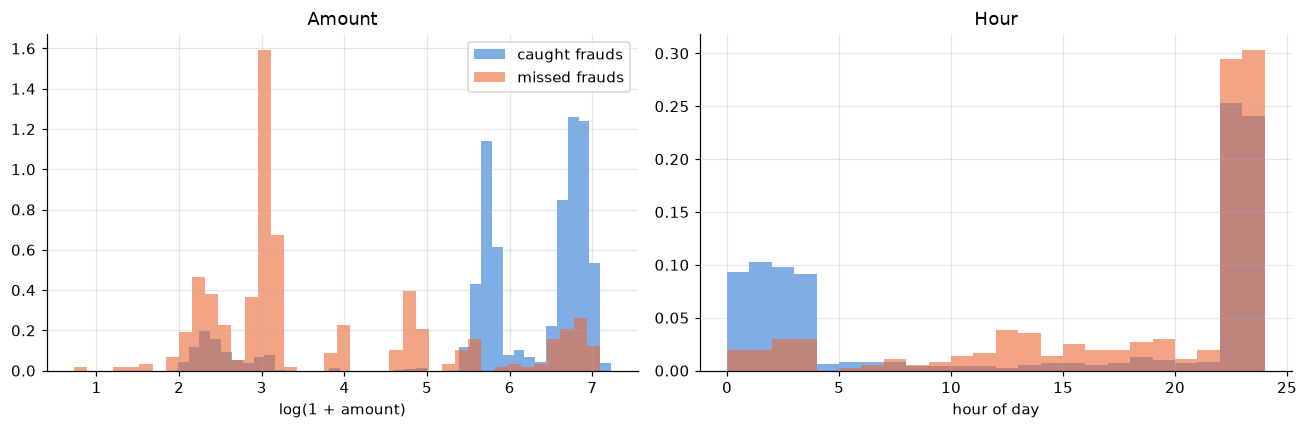

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, g, color in [("caught frauds", caught, LEGIT), ("missed frauds", missed, FRAUD)]:
    axes[0].hist(np.log1p(g["amt"]), bins=40, density=True, alpha=0.6, color=color, label=name)
    axes[1].hist(g["hour"], bins=range(25), density=True, alpha=0.6, color=color, label=name)
axes[0].set_xlabel("log(1 + amount)")
axes[0].set_title("Amount")
axes[1].set_xlabel("hour of day")
axes[1].set_title("Hour")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "error_analysis_amount_hour.png", bbox_inches="tight")

Share of each group by store category, sorted by where the network misses the most:

In [15]:
pd.DataFrame(
    {name: g["category"].value_counts(normalize=True) for name, g in groups.items()}
).round(3).sort_values("missed frauds", ascending=False)

,missed frauds,caught frauds,legit
category,,,
personal_care,0.187,NaN,0.070
kids_pets,0.165,0.004,0.087
misc_pos,0.132,0.017,0.061
food_dining,0.113,0.003,0.070
health_fitness,0.102,NaN,0.067
travel,0.083,NaN,0.031
grocery_net,0.047,0.012,0.035
shopping_pos,0.036,0.128,0.090
home,0.033,0.030,0.095


### False alarms: which legit purchases get flagged?

Missing a fraud is not the only error. Every legit purchase flagged as fraud is a customer whose card gets blocked for nothing, so it is worth asking the same question about them.

In [16]:
flagged = legit[legit["score"] >= THRESHOLD]
not_flagged = legit[legit["score"] < THRESHOLD]
print(f"Legit transactions in cv: {len(legit)} | flagged as fraud: {len(flagged)}")

pd.DataFrame({
    name: {
        "transactions": len(g),
        "median amount": g["amt"].median(),
        "share at night (22h-3h)": g["hour"].isin(NIGHT_HOURS).mean(),
        "median score": g["score"].median(),
    }
    for name, g in {"flagged legit": flagged, "not flagged legit": not_flagged, "caught frauds": caught}.items()
}).round(3)

Legit transactions in cv: 369539 | flagged as fraud: 754


,flagged legit,not flagged legit,caught frauds
transactions,754.000,368785.000,1923.000
median amount,736.365,47.450,736.280
share at night (22h-3h),0.508,0.232,0.879
median score,0.690,0.000,0.986


### One card, up close

Statistics hide the story of a single card. Below are all transactions of the card with the most missed frauds, from two days before its first fraud until the last one.

In [17]:
card = missed["cc_num"].value_counts().index[0]
card_frauds = frauds[frauds["cc_num"] == card]
window = (cv["cc_num"] == card) & cv["trans_date_trans_time"].between(
    card_frauds["trans_date_trans_time"].min() - pd.Timedelta(days=2),
    card_frauds["trans_date_trans_time"].max(),
)
cv.loc[window, ["trans_date_trans_time", "category", "amt", "is_fraud", "score"]].round(3)

/var/folders/z8/k3_rp8d93l9bj0jrg7tqvysr0000gn/T/ipykernel_15962/1033228747.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  cv.loc[window, ["trans_date_trans_time", "category", "amt", "is_fraud", "score"]].round(3)


,trans_date_trans_time,category,amt,is_fraud,score
1278958,2020-06-15 01:55:33,grocery_pos,115.77,0,0.000
1279160,2020-06-15 03:17:23,grocery_pos,64.22,0,0.000
1279674,2020-06-15 07:06:37,grocery_net,75.14,0,0.000
1281199,2020-06-15 15:47:54,shopping_pos,3.50,0,0.000
1281608,2020-06-15 17:42:42,personal_care,20.43,0,0.022
1283436,2020-06-16 04:14:34,gas_transport,58.64,0,0.000
1283561,2020-06-16 05:15:08,grocery_pos,123.74,0,0.000
1284893,2020-06-16 14:17:11,home,56.19,0,0.000
1285713,2020-06-16 18:38:59,home,67.00,0,0.000
1286684,2020-06-16 23:54:28,shopping_pos,4.57,0,0.000


### Tagging a sample of errors

The tables above compare averages. The course recipe for error analysis goes one step further:

1. Draw a random sample of about 100 errors from the cv set (never the test set).
2. Tag each error with the traits it shows. Tags may overlap: one error can be both "small" and "daytime".
3. Count the tags and work on the biggest groups first. Fixing every error in a group removes at most that group's share of the errors, which is the ceiling of any idea aimed at it.

Every column here is readable, so the tags can be written as rules instead of read one by one. One tag needs information the model never sees: what the card did in the 24 hours before each purchase. `card_history` counts only earlier purchases of the same card, which is what a bank knows when the purchase arrives.

In [18]:
# Train and cv together, so the first days of cv still see the card's history from late 2019.
activity = card_history(pd.concat([split.train, split.cv]))
cv = cv.join(activity)

# Store categories whose fraud rate in train is above the overall rate.
train_rate = split.train.groupby("category")["is_fraud"].mean()
risky_categories = train_rate[train_rate > split.train["is_fraud"].mean()].index
print("High-risk categories:", list(risky_categories))

missed = cv.loc[missed.index]
flagged = cv.loc[flagged.index]
night = cv["hour"].isin(NIGHT_HOURS)
large_recently = cv["large_tx_last_24h"] >= 1

High-risk categories: ['grocery_pos', 'misc_net', 'shopping_net', 'shopping_pos']


**Missed frauds**, 100 sampled at random:

In [19]:
count_tags(sample_errors(missed), {
    "small purchase (under $100)": cv["amt"] < 100,
    "daytime (4h to 21h)": ~night,
    "low-risk store category": ~cv["category"].isin(risky_categories),
    "card already in a burst (large purchase in the last 24h)": large_recently,
})

,errors,share_%
low-risk store category,92,92.0
card already in a burst (large purchase in the last 24h),92,92.0
small purchase (under $100),72,72.0
daytime (4h to 21h),23,23.0


**False alarms** (legit purchases flagged as fraud), 100 sampled at random:

In [20]:
count_tags(sample_errors(flagged), {
    "large purchase (over $200)": cv["amt"] > 200,
    "at night (22h to 3h)": night,
    "high-risk store category": cv["category"].isin(risky_categories),
    "calm card history (no large purchase in the last 24h)": ~large_recently,
})

,errors,share_%
calm card history (no large purchase in the last 24h),85,85.0
large purchase (over $200),80,80.0
at night (22h to 3h),63,63.0
high-risk store category,63,63.0


### The card's last 24 hours, for every group

The burst tag stands out on both sides. Checking it on all cv transactions, not just the samples:

In [21]:
groups = {
    "missed frauds": cv[(cv["is_fraud"] == 1) & (cv["score"] < THRESHOLD)],
    "caught frauds": cv[(cv["is_fraud"] == 1) & (cv["score"] >= THRESHOLD)],
    "false alarms": cv[(cv["is_fraud"] == 0) & (cv["score"] >= THRESHOLD)],
    "legit, not flagged": cv[(cv["is_fraud"] == 0) & (cv["score"] < THRESHOLD)],
}
pd.DataFrame({
    name: {
        "share with a large purchase in the last 24h": (g["large_tx_last_24h"] >= 1).mean(),
        "share with 2+ night purchases in the last 24h": (g["night_tx_last_24h"] >= 2).mean(),
        "median purchases in the last 24h": g["tx_last_24h"].median(),
    }
    for name, g in groups.items()
}).round(2)

,missed frauds,caught frauds,false alarms,"legit, not flagged"
share with a large purchase in the last 24h,0.92,0.86,0.16,0.13
share with 2+ night purchases in the last 24h,0.81,0.73,0.21,0.18
median purchases in the last 24h,4.00,4.00,3.00,3.00


### What the errors have in common

**Missed frauds are small purchases made inside a burst.** The median missed fraud is about \$21, against \$736 for the frauds the network catches, and 92 of the 100 sampled happen in low-risk store categories such as personal care or kids and pets. Viewed alone, each one looks like an ordinary purchase. What gives them away is the card: in 92 of the 100, the same card had already made a large purchase in the previous 24 hours. Fraudsters mix small purchases into the burst, and the network, which scores each transaction on its own, cannot see the burst.

**False alarms are large, isolated purchases.** On the surface they look like the frauds the network catches: 80 of the 100 sampled are above \$200, and most happen at night or in high-risk categories. But 85 of the 100 come from cards with a calm recent history. Across all cv transactions, only 16% of false alarms follow a large purchase in the previous 24 hours, close to the 13% of ordinary legit purchases and far from the 86% to 92% of frauds.

**The card above tells the same story.** For two days it makes ordinary purchases. At 00:33 on 17 June the burst starts with five large purchases in three hours, all caught. Over the next two days the card keeps making large purchases, which the network mostly catches, mixed with \$10 to \$20 purchases in kids and pets, personal care, health and travel stores, which it lets through. It also misses two large purchases made at 05:08 and 11:09, outside the night hours where most frauds happen.

**Where to go next.** The other tags describe what the errors look like but cannot separate them from legit purchases, since most legit purchases are also small, in low-risk categories, or both. Recent card activity is the one trait that differs sharply between the errors and the transactions they are confused with. Features describing it would address up to 92% of the missed frauds and 85% of the false alarms in the samples, the highest ceiling of any idea here.

## Conclusions

1. **Bias or variance?** Neither shows up as a problem. J_train and J_cv overlap for all 300 epochs, so the network generalizes to the cv period with no sign of high variance. Both curves were still creeping down at the end, but they barely move after epoch 100, so more epochs would add little. The error analysis points to missing information rather than to a model that is too small or too regularized.

2. **Neural network vs logistic regression.** The network reaches a PR-AUC of 0.88 on cv, against 0.35 for the best logistic regression. The three-seed search puts the network at 0.855 ± 0.022, so the gap is far larger than the run-to-run noise. The network learns the non-linear patterns (risky hours on both sides of midnight, amount combined with store category) that a linear model cannot express.

3. **Precision-recall curve.** The network is better across the whole recall range. It keeps precision close to 1 up to about 60% recall and around 0.9 at 75% recall, while neither logistic regression gets above about 0.77 precision at any recall. Beyond roughly 80% recall the network's precision falls quickly: the frauds left to catch are the small purchases described above, which look like ordinary transactions.

4. **Next steps.** Add card-history features computed only from earlier purchases of the same card, such as the number of purchases, night purchases and large purchases in the last 24 hours. The error analysis gives them a ceiling of 92% of the missed frauds and 85% of the false alarms. Then choose the decision threshold by cost on cv, and only after that evaluate the final model once on the test set.